<a href="https://colab.research.google.com/github/tasnimfarhat27/Customer-Churn-Prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Mount Google Drive and install libraries
!pip install xgboost lightgbm shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap

# Mount Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Cell 2: Load the dataset using your Google Drive folder path
file_path = '/content/drive/MyDrive/Cutomer Churn Prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(file_path)
print("✓ Dataset successfully loaded from Google Drive!")
print(f"Dataset Shape: {df.shape}")
df.head()

✓ Dataset successfully loaded from Google Drive!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Cell 3: Data Cleaning & Feature Preprocessing Setup

# 1. Clean whitespace strings in TotalCharges and cast to float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)

# 2. Encode Target variable (Yes = 1, No = 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 3. Separate features (X) and target (y), dropping customerID
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Build ColumnTransformer for numerical scaling and categorical encoding
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X.columns if col not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# 6. Fit preprocessor on training data and transform both sets
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"✓ Processed Training Matrix Shape: {X_train_proc.shape}")
print(f"✓ Processed Testing Matrix Shape:  {X_test_proc.shape}")

✓ Processed Training Matrix Shape: (5634, 30)
✓ Processed Testing Matrix Shape:  (1409, 30)


In [4]:
# Cell 4: Model Training

# Calculate class ratio for imbalance handling in boosting algorithms
scale_pos_ratio = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, weights='distance'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=8, random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_pos_ratio, n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss'),
    "LightGBM": LGBMClassifier(scale_pos_weight=scale_pos_ratio, n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, verbose=-1)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_proc, y_train)
    trained_models[name] = model
    print(f"✓ Trained: {name}")

✓ Trained: Logistic Regression
✓ Trained: K-Nearest Neighbors
✓ Trained: Decision Tree
✓ Trained: Random Forest
✓ Trained: XGBoost
✓ Trained: LightGBM


In [5]:
# Cell 5: Benchmark Dataframe Generation
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_proc)
    y_prob = model.predict_proba(X_test_proc)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
comparison_df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.7480,0.5161,0.8128,0.6314,0.8440
1,Random Forest,0.7594,0.5318,0.7834,0.6335,0.8432
2,LightGBM,0.7509,0.5200,0.7995,0.6301,0.8419
3,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8417
4,Decision Tree,0.7346,0.5000,0.8075,0.6176,0.8308
5,K-Nearest Neighbors,0.7580,0.5447,0.5374,0.5410,0.7795


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


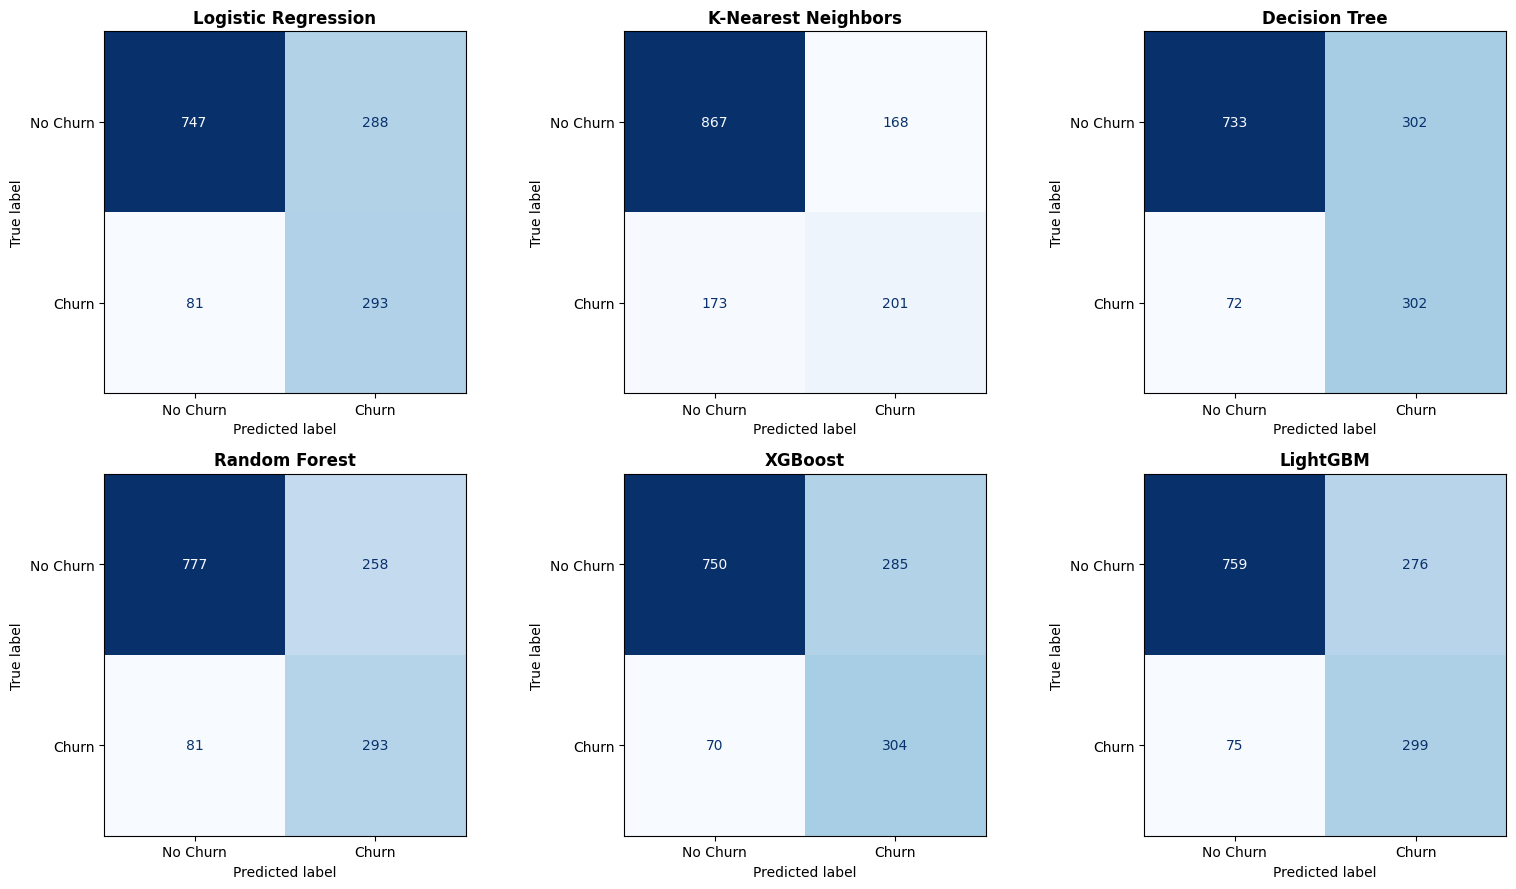

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


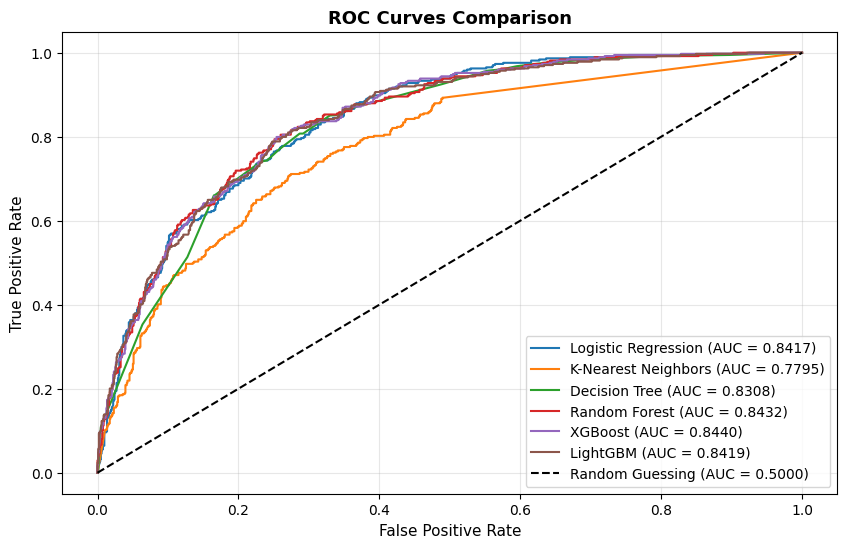

In [6]:
# Cell 6: Visualizations (Confusion Matrices & ROC Overlay)

# 1. Confusion Matrices Grid
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_proc)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(name, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Comparative ROC Curves Overlay
plt.figure(figsize=(10, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test_proc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing (AUC = 0.5000)")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("ROC Curves Comparison", fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

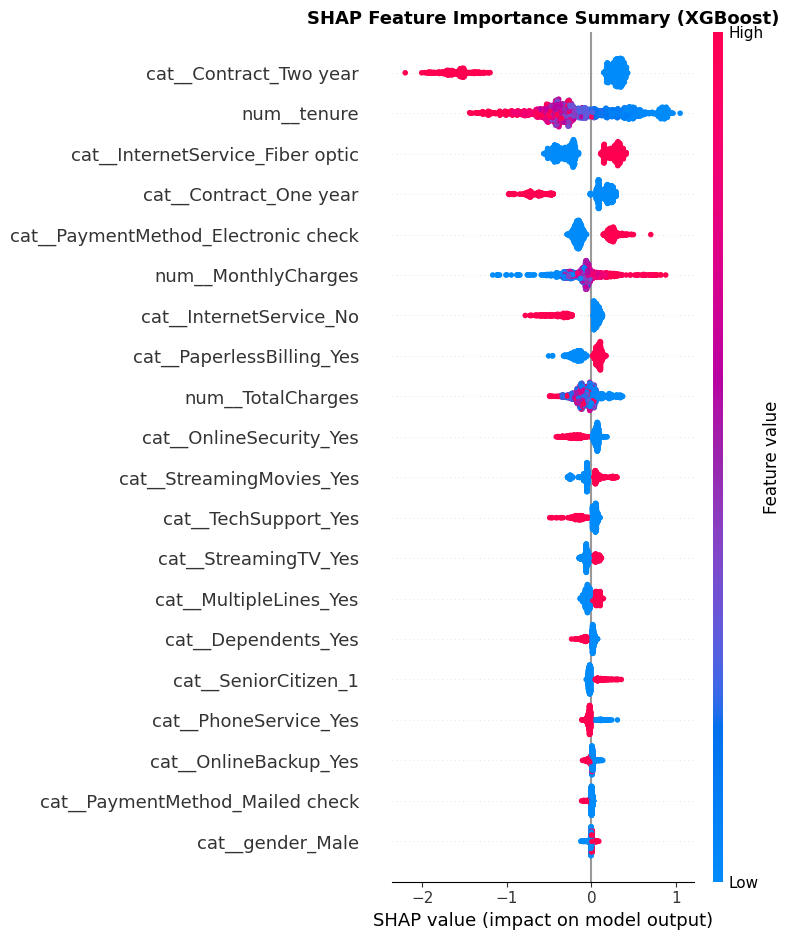

In [7]:
# Cell 7: SHAP Summary Plot
xgb_model = trained_models["XGBoost"]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_proc)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_proc, feature_names=feature_names, show=False)
plt.title("SHAP Feature Importance Summary (XGBoost)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# Cell 8: Save trained model pipeline directly to your Drive folder
from sklearn.pipeline import Pipeline

production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', trained_models['XGBoost'])
])

save_path = '/content/drive/MyDrive/Cutomer Churn Prediction/telco_churn_pipeline.pkl'
joblib.dump(production_pipeline, save_path)

print(f"✓ Production pipeline saved successfully to Drive: {save_path}")

✓ Production pipeline saved successfully to Drive: /content/drive/MyDrive/Cutomer Churn Prediction/telco_churn_pipeline.pkl


In [9]:
# ===================================================================
# Cell 9: Light Pink Theme Executive Churn Dashboard (Gradio UI)
# ===================================================================
!pip install gradio -q

import gradio as gr
import pandas as pd
import joblib

# 1. Load trained backend production pipeline
pipeline_path = '/content/drive/MyDrive/Cutomer Churn Prediction/telco_churn_pipeline.pkl'
pipeline = joblib.load(pipeline_path)

# 2. Real-Time Prediction & Dynamic Dashboard HTML Generator
def predict_churn(gender, senior_citizen, partner, dependents, tenure,
                  phone_service, multiple_lines, internet_service,
                  online_security, online_backup, device_protection,
                  tech_support, streaming_tv, streaming_movies,
                  contract, paperless_billing, payment_method,
                  monthly_charges, total_charges):

    # Construct input DataFrame
    input_df = pd.DataFrame([{
        'gender': gender,
        'SeniorCitizen': int(senior_citizen),
        'Partner': partner,
        'Dependents': dependents,
        'tenure': float(tenure),
        'PhoneService': phone_service,
        'MultipleLines': multiple_lines,
        'InternetService': internet_service,
        'OnlineSecurity': online_security,
        'OnlineBackup': online_backup,
        'DeviceProtection': device_protection,
        'TechSupport': tech_support,
        'StreamingTV': streaming_tv,
        'StreamingMovies': streaming_movies,
        'Contract': contract,
        'PaperlessBilling': paperless_billing,
        'PaymentMethod': payment_method,
        'MonthlyCharges': float(monthly_charges),
        'TotalCharges': float(total_charges)
    }])

    # Predict probabilities via XGBoost production pipeline
    churn_prob = float(pipeline.predict_proba(input_df)[0][1])
    prob_percentage = round(churn_prob * 100, 1)
    retain_percentage = round(100.0 - prob_percentage, 1)

    # Determine risk label & gauge color stroke
    if churn_prob >= 0.60:
        risk_label = "High Risk"
        stroke_color = "#e11d48"
        rec = "High churn risk detected. Immediately offer a 1-year contract discount or a complimentary tech support upgrade."
    elif churn_prob >= 0.35:
        risk_label = "Moderate Risk"
        stroke_color = "#d97706"
        rec = "Customer is on the fence. Proactively reach out regarding internet package optimizations."
    else:
        risk_label = "Low Risk"
        stroke_color = "#0284c7"
        rec = "Account is stable. Standard automated marketing lifecycle path recommended."

    # Semi-Circle Arc SVG Offset Calculation (Perimeter ~125.66px)
    dash_offset = round(125.66 * (1.0 - (prob_percentage / 100.0)), 1)

    # ---------------------------------------------------------------
    # Section 1: Top Risk Factors (Reference Card)
    # ---------------------------------------------------------------
    risk_list = []
    if contract == "Month-to-month":
        risk_list.append(("Month-to-Month Contract", 88, "#fef3c7", "#d97706"))
    if internet_service == "Fiber optic":
        risk_list.append(("Fiber Optic Connection", 76, "#e0f2fe", "#0284c7"))
    if tech_support in ["No", "No internet service"]:
        risk_list.append(("No Tech Support Add-on", 68, "#ffe4e6", "#e11d48"))
    if tenure <= 12:
        risk_list.append(("Short Tenure (<= 12 Months)", 82, "#fef3c7", "#b45309"))
    if payment_method == "Electronic check":
        risk_list.append(("Electronic Check Billing", 64, "#e0f2fe", "#0369a1"))
    if online_security in ["No", "No internet service"]:
        risk_list.append(("No Online Security", 58, "#ffe4e6", "#be123c"))

    if len(risk_list) < 3:
        risk_list.append(("High Monthly Charges", 52, "#e0f2fe", "#0284c7"))

    top_factors = risk_list[:3]

    top_factors_html = ""
    for item_name, item_pct, bar_bg, bar_accent in top_factors:
        top_factors_html += f"""
        <div style="margin-bottom: 10px;">
            <div style="display: flex; justify-content: space-between; font-size: 11px; font-weight: 700; color: #334155; margin-bottom: 4px;">
                <span>{item_name}</span>
                <span>{item_pct}%</span>
            </div>
            <div style="width: 100%; background: #f1f5f9; height: 12px; border-radius: 20px; overflow: hidden;">
                <div style="width: {item_pct}%; background: {bar_bg}; height: 100%; border-radius: 20px; border-left: 4px solid {bar_accent};"></div>
            </div>
        </div>
        """

    # ---------------------------------------------------------------
    # Section 2: Customer Value (Reference Card)
    # ---------------------------------------------------------------
    if monthly_charges >= 75:
        val_text, val_pct, val_bg, val_color = "High Customer Value", 85, "#e0f2fe", "#0284c7"
    elif monthly_charges >= 45:
        val_text, val_pct, val_bg, val_color = "Medium Customer Value", 60, "#fef3c7", "#d97706"
    else:
        val_text, val_pct, val_bg, val_color = "Standard Customer Value", 40, "#f3f4f6", "#64748b"

    # ---------------------------------------------------------------
    # Section 3: Customer Propensity Cards (Reference Card Grid)
    # ---------------------------------------------------------------
    services_count = sum([
        1 for s in [phone_service, online_security, online_backup, device_protection, tech_support, streaming_tv, streaming_movies]
        if s == "Yes"
    ])
    eng_score = int(round((services_count / 7.0) * 100))

    # Assemble Dashboard HTML Card
    html_dashboard = f"""
    <div style="background: #ffffff; border-radius: 24px; padding: 28px; box-shadow: 0 12px 36px rgba(190, 24, 93, 0.08); border: 1px solid #fbcfe8; font-family: system-ui, -apple-system, sans-serif;">

        <!-- Header Row -->
        <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px;">
            <h3 style="margin: 0; font-size: 19px; font-weight: 800; color: #0f172a;">Churn Risk Score</h3>
            <span style="background: #fdf2f8; color: #db2777; padding: 6px 14px; border-radius: 20px; font-size: 12px; font-weight: 700; border: 1px solid #fbcfe8;">
                ✦ AI Powered
            </span>
        </div>

        <!-- Arc Gauge Meter -->
        <div style="text-align: center; position: relative; width: 230px; margin: 10px auto 0 auto;">
            <svg viewBox="0 0 100 55" style="width: 100%; display: block;">
                <path d="M 10 50 A 40 40 0 0 1 90 50" fill="none" stroke="#f1f5f9" stroke-width="9" stroke-linecap="round" />
                <path d="M 10 50 A 40 40 0 0 1 90 50" fill="none" stroke="{stroke_color}" stroke-width="9" stroke-linecap="round"
                      stroke-dasharray="125.66" stroke-dashoffset="{dash_offset}" style="transition: stroke-dashoffset 1s ease-in-out;" />
            </svg>
            <div style="position: absolute; bottom: 0; left: 0; right: 0; text-align: center;">
                <div style="font-size: 38px; font-weight: 800; color: #1e293b; line-height: 1;">{prob_percentage}%</div>
                <div style="font-size: 13px; font-weight: 700; color: #64748b; margin-top: 4px;">{risk_label}</div>
            </div>
        </div>
        <div style="display: flex; justify-content: space-between; width: 75%; margin: 6px auto 22px auto; font-size: 12px; color: #94a3b8; font-weight: 700;">
            <span>0</span>
            <span>100</span>
        </div>

        <!-- Top Risk Factors -->
        <div style="margin-bottom: 22px;">
            <h4 style="margin: 0 0 10px 0; font-size: 14px; font-weight: 800; color: #0f172a;">Top Risk Factors</h4>
            {top_factors_html}
        </div>

        <!-- Customer Value -->
        <div style="margin-bottom: 22px;">
            <h4 style="margin: 0 0 10px 0; font-size: 14px; font-weight: 800; color: #0f172a;">Customer Value</h4>
            <div style="background: {val_bg}; border-radius: 20px; padding: 8px 16px; display: flex; align-items: center; justify-content: space-between;">
                <span style="font-size: 12px; font-weight: 700; color: {val_color};">{val_text}</span>
                <div style="width: 45%; background: #ffffff; height: 8px; border-radius: 10px; overflow: hidden;">
                    <div style="width: {val_pct}%; background: {val_color}; height: 100%;"></div>
                </div>
            </div>
        </div>

        <!-- Customer Propensity Cards -->
        <div style="margin-bottom: 22px;">
            <h4 style="margin: 0 0 10px 0; font-size: 14px; font-weight: 800; color: #0f172a;">Customer Propensity</h4>
            <div style="display: grid; grid-template-columns: 1fr 1fr 1fr; gap: 10px;">

                <div style="background: #e0f2fe; border-radius: 16px; padding: 14px 10px; text-align: center;">
                    <div style="font-size: 11px; font-weight: 700; color: #0369a1; margin-bottom: 6px; line-height: 1.2;">Churn<br>Probability</div>
                    <div style="font-size: 17px; font-weight: 800; color: #0c4a6e;">{prob_percentage}%</div>
                    <div style="background: #ffffff; height: 6px; border-radius: 10px; margin-top: 8px; overflow: hidden;">
                        <div style="width: {prob_percentage}%; background: #0284c7; height: 100%;"></div>
                    </div>
                </div>

                <div style="background: #fef3c7; border-radius: 16px; padding: 14px 10px; text-align: center;">
                    <div style="font-size: 11px; font-weight: 700; color: #b45309; margin-bottom: 6px; line-height: 1.2;">Retention<br>Probability</div>
                    <div style="font-size: 17px; font-weight: 800; color: #78350f;">{retain_percentage}%</div>
                    <div style="background: #ffffff; height: 6px; border-radius: 10px; margin-top: 8px; overflow: hidden;">
                        <div style="width: {retain_percentage}%; background: #d97706; height: 100%;"></div>
                    </div>
                </div>

                <div style="background: #ffe4e6; border-radius: 16px; padding: 14px 10px; text-align: center;">
                    <div style="font-size: 11px; font-weight: 700; color: #be123c; margin-bottom: 6px; line-height: 1.2;">Engagement<br>Score</div>
                    <div style="font-size: 17px; font-weight: 800; color: #881337;">{eng_score}/100</div>
                    <div style="background: #ffffff; height: 6px; border-radius: 10px; margin-top: 8px; overflow: hidden;">
                        <div style="width: {eng_score}%; background: #e11d48; height: 100%;"></div>
                    </div>
                </div>

            </div>
        </div>

        <!-- Business Action Banner -->
        <div style="background: #fff5f8; border-left: 4px solid {stroke_color}; border-radius: 12px; padding: 14px 16px;">
            <div style="font-size: 11px; font-weight: 800; color: #9f1239; text-transform: uppercase; letter-spacing: 0.5px; margin-bottom: 4px;">
                💡 Recommended Business Action
            </div>
            <div style="font-size: 13px; color: #334155; line-height: 1.4; font-weight: 600;">
                {rec}
            </div>
        </div>

    </div>
    """

    probabilities = {"Churn Probability": float(churn_prob), "Retention Probability": float(1.0 - churn_prob)}
    return html_dashboard, probabilities

# 3. Custom CSS Rules for Light Pink Page Background & Styling
custom_css = """
body { background-color: #fce7f3 !important; }
.gradio-container { max-width: 1240px !important; margin: 0 auto !important; background-color: #fce7f3 !important; }

.hero-banner {
    background: linear-gradient(135deg, #831843 0%, #500724 100%);
    border-radius: 20px;
    padding: 24px 30px;
    color: white;
    margin-bottom: 24px;
    box-shadow: 0 10px 25px rgba(131, 24, 67, 0.2);
}
.hero-banner h1 { font-size: 26px !important; font-weight: 800 !important; color: #ffffff !important; margin: 0 0 6px 0 !important; }
.hero-banner p { font-size: 14px !important; color: #fbcfe8 !important; margin: 0 !important; }

.action-btn {
    background: linear-gradient(135deg, #db2777 0%, #be185d 100%) !important;
    color: white !important;
    font-weight: 700 !important;
    font-size: 15px !important;
    border-radius: 12px !important;
    border: none !important;
    padding: 12px 24px !important;
    box-shadow: 0 4px 14px rgba(219, 39, 119, 0.35) !important;
    transition: all 0.2s ease !important;
}
.action-btn:hover {
    transform: translateY(-2px) !important;
    box-shadow: 0 6px 20px rgba(219, 39, 119, 0.45) !important;
}
"""

# 4. Construct Blocks UI Layout
with gr.Blocks(theme=gr.themes.Soft(primary_hue="pink", neutral_hue="slate"), css=custom_css) as demo:

    with gr.Row(elem_classes=["hero-banner"]):
        with gr.Column(scale=3):
            gr.Markdown(
                """
                # 🏃‍♂️ CUSTOMER CHURN INTELLIGENCE PORTAL
                *Predict churn probability, evaluate top risk drivers, and trigger automated retention actions.*
                """
            )
        with gr.Column(scale=1, min_width=120):
            gr.Markdown("<div style='text-align: right; font-size: 32px;'>🚪🏃</div>")

    with gr.Row(equal_height=False):
        with gr.Column(scale=3):
            with gr.Tabs():
                with gr.Tab("👤 Customer Profile"):
                    with gr.Row():
                        gender = gr.Radio(["Female", "Male"], value="Female", label="Gender")
                        senior_citizen = gr.Radio([0, 1], value=0, label="Senior Citizen (1=Yes, 0=No)")
                    with gr.Row():
                        partner = gr.Radio(["Yes", "No"], value="No", label="Has Partner?")
                        dependents = gr.Radio(["Yes", "No"], value="No", label="Has Dependents?")
                    tenure = gr.Slider(minimum=0, maximum=72, value=12, step=1, label="Tenure Duration (Months)")

                with gr.Tab("🔌 Subscribed Services"):
                    with gr.Row():
                        phone_service = gr.Radio(["Yes", "No"], value="Yes", label="Phone Service")
                        multiple_lines = gr.Dropdown(["No phone service", "No", "Yes"], value="No", label="Multiple Lines")
                        internet_service = gr.Dropdown(["DSL", "Fiber optic", "No"], value="Fiber optic", label="Internet Service")
                    with gr.Row():
                        online_security = gr.Dropdown(["No internet service", "No", "Yes"], value="No", label="Online Security")
                        online_backup = gr.Dropdown(["No internet service", "No", "Yes"], value="No", label="Online Backup")
                        device_protection = gr.Dropdown(["No internet service", "No", "Yes"], value="No", label="Device Protection")
                    with gr.Row():
                        tech_support = gr.Dropdown(["No internet service", "No", "Yes"], value="No", label="Tech Support")
                        streaming_tv = gr.Dropdown(["No internet service", "No", "Yes"], value="Yes", label="Streaming TV")
                        streaming_movies = gr.Dropdown(["No internet service", "No", "Yes"], value="Yes", label="Streaming Movies")

                with gr.Tab("💳 Contract & Billing"):
                    contract = gr.Dropdown(["Month-to-month", "One year", "Two year"], value="Month-to-month", label="Contract Type")
                    with gr.Row():
                        paperless_billing = gr.Radio(["Yes", "No"], value="Yes", label="Paperless Billing")
                        payment_method = gr.Dropdown([
                            "Electronic check", "Mailed check",
                            "Bank transfer (automatic)", "Credit card (automatic)"
                        ], value="Electronic check", label="Payment Method")
                    with gr.Row():
                        monthly_charges = gr.Number(value=85.50, label="Monthly Charges ($)")
                        total_charges = gr.Number(value=1026.00, label="Total Charges ($)")

            predict_btn = gr.Button("⚡ Evaluate Risk Profile", elem_classes=["action-btn"], size="lg")

        with gr.Column(scale=2):
            result_dashboard = gr.HTML(label="Executive Dashboard")
            probability_bar = gr.Label(label="Confidence Scores")

    predict_btn.click(
        fn=predict_churn,
        inputs=[
            gender, senior_citizen, partner, dependents, tenure,
            phone_service, multiple_lines, internet_service,
            online_security, online_backup, device_protection,
            tech_support, streaming_tv, streaming_movies,
            contract, paperless_billing, payment_method,
            monthly_charges, total_charges
        ],
        outputs=[result_dashboard, probability_bar]
    )

demo.launch(share=True)

/tmp/ipykernel_2741/4290442233.py:250: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="pink", neutral_hue="slate"), css=custom_css) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/28 10:36:47 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>